# CheXWorld on NIH ChestX-ray14 dataset

In [1]:
# Imports
import importlib
import json
import os
import shutil
import socket
import subprocess
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image
from sklearn.metrics import confusion_matrix, precision_recall_curve, roc_curve

SETUP_START = time.perf_counter()
WORK = Path('/kaggle/working')
INPUT = Path('/kaggle/input')
WORK.mkdir(parents=True, exist_ok=True)
RUNTIME = WORK / 'chexworld_nih_runtime.py'


In [2]:
# Set the NIH training profile 
DATA_ROOT = ''
PRETRAINED_WEIGHTS = ''
SPLIT_ROOT = ''
RESTORE_RESULTS = ''
RUN_NAME = 'chexworld_nih'
SEEDS = [0]

EPOCHS = 15
WARMUP_EPOCHS = 1
LEARNING_RATE = 1e-4
MIN_LR = 1e-6
WEIGHT_DECAY = 0.05
LAYER_DECAY = 0.75
DROP_PATH = 0.6
MICRO_BATCH = 32
ACCUMULATION = 4
EVAL_BATCH = 64
NUM_WORKERS = 2
CLIP_GRAD = 1.0
PATIENCE = 15

REPO_COMMIT = '090102758801dc097f53c49d135b835570c8d173'
CHECKPOINT_SHA256 = '175d2c75971daea772d1f338a8cc81540db60fa48f55cbbd9006b2b9b3576a9a'
REPO = WORK / 'CheXWorld-source'
CODE_DIR = WORK / 'chexworld_official'
RESULTS = WORK / RUN_NAME
RESULTS.mkdir(parents=True, exist_ok=True)


In [3]:
# Set the verified official annotation resources
SPLIT_FILES = {
    'train': '1L-ATaj93zVWMYFftGePxAnhCsKyfSlVY',
    'val': '1sAyL-CvvJjQwKp60ndsCf_M2hdZaBOn8',
    'test': '1uUUF3jeE1lNjTh3JUTFuNpnFUPYgxUxB',
}
SPLIT_HASHES = {
    'train': '60cc170f312a2301e5c9a8860fe36437e0ee632b4da8a890b855a669fe3069f4',
    'val': '4ea551a628d287bbe19f474408975acfbee98437245956531101cbdab5c4c090',
    'test': '7fa6a1865c16b416ed0cd96954fbbb3945f8ea20c39c22521e068859cda4c7cf',
}
EXPECTED_COUNTS = {'train': 75312, 'val': 11212, 'test': 25596}


In [4]:
# Install the small compatibility dependencies
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '--no-deps',
                'timm==0.9.16', 'einops==0.8.1'], check=True)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 37.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 3.6 MB/s eta 0:00:00


CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', '--no-deps', 'timm==0.9.16', 'einops==0.8.1'], returncode=0)

In [5]:
# Check both GPUs and restore saved results if provided
GPU_COUNT = torch.cuda.device_count()
if GPU_COUNT != 2:
    raise RuntimeError('Select GPU T4 x2 in Kaggle Session options.')
print('Using:', ', '.join(torch.cuda.get_device_name(i) for i in range(GPU_COUNT)))
print(f'Effective batch: {MICRO_BATCH * GPU_COUNT * ACCUMULATION} | maximum epochs per seed: {EPOCHS}')
if RESTORE_RESULTS and not any(RESULTS.iterdir()):
    restore_root = Path(RESTORE_RESULTS)
    if not (restore_root / 'config.json').is_file():
        raise FileNotFoundError('RESTORE_RESULTS must point to the saved results folder containing config.json.')
    shutil.copytree(restore_root, RESULTS, dirs_exist_ok=True)
    print('Restored previous results:', restore_root)


Using: Tesla T4, Tesla T4
Effective batch: 256 | maximum epochs per seed: 15


In [6]:
# Download the pinned official source
if not (REPO / '.git').exists():
    subprocess.run(['git', 'clone', '-q', 'https://github.com/LeapLabTHU/CheXWorld.git', str(REPO)], check=True)
subprocess.run(['git', '-C', str(REPO), 'checkout', '-q', REPO_COMMIT], check=True)
revision = subprocess.check_output(['git', '-C', str(REPO), 'rev-parse', 'HEAD'], text=True).strip()
if revision != REPO_COMMIT:
    raise RuntimeError('The source revision does not match the verified release.')


In [7]:
%%writefile {RUNTIME}
# Save the download and official-source helpers
import ast
import contextlib
import hashlib
import html
import importlib
import json
import math
import os
import random
import re
import shutil
import sys
import time
from datetime import timedelta
from pathlib import Path
from types import SimpleNamespace
import numpy as np
import pandas as pd
import requests
import torch
import torch.distributed as dist
from PIL import Image
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix,
                             precision_recall_curve, precision_recall_fscore_support, roc_auc_score)
from torch import nn
from torch.utils.data import DataLoader, Dataset, DistributedSampler, Subset
import gc


LABELS = ['Atelectasis', 'Cardiomegaly', 'Effusion', 'Infiltration', 'Mass', 'Nodule', 'Pneumonia', 'Pneumothorax', 'Consolidation', 'Edema', 'Emphysema', 'Fibrosis', 'Pleural_Thickening', 'Hernia']


def sha256(path):
    digest = hashlib.sha256()
    with open(path, 'rb') as stream:
        for chunk in iter(lambda: stream.read(8 * 1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()


def download_weights(destination, expected_hash):
    destination = Path(destination)
    if destination.exists() and sha256(destination) == expected_hash:
        return destination
    url = 'https://drive.usercontent.google.com/download'
    params = {'id': '1QKUhIWIicl65UXJIGSh7_rYaq5i08iVn', 'export': 'download'}
    with requests.Session() as session:
        response = session.get(url, params=params, stream=True, timeout=(30, 120))
        response.raise_for_status()
        if 'text/html' in response.headers.get('Content-Type', ''):
            page = response.text
            params = {html.unescape(k): html.unescape(v) for k, v in
                      re.findall(r'name="([^"]+)" value="([^"]+)"', page)}
            response.close()
            if params.get('confirm') != 't':
                raise RuntimeError('Drive did not offer the weights. Attach chexworld_pretrained.tar as input.')
            response = session.get(url, params=params, stream=True, timeout=(30, 120))
            response.raise_for_status()
        if 'text/html' in response.headers.get('Content-Type', ''):
            response.close()
            raise RuntimeError('Drive download is unavailable. Attach the official weights as notebook input.')
        destination.parent.mkdir(parents=True, exist_ok=True)
        temporary = destination.with_suffix('.partial')
        with temporary.open('wb') as stream:
            for chunk in response.iter_content(4 * 1024 * 1024):
                stream.write(chunk)
        response.close()
    if sha256(temporary) != expected_hash:
        raise ValueError('Downloaded weights do not match the verified official checkpoint.')
    temporary.replace(destination)
    return destination


def prepare_official_code(repo, destination):
    destination = Path(destination)
    destination.mkdir(parents=True, exist_ok=True)
    (destination / '__init__.py').write_text('')
    files = ['jepa_vit.py', 'jepa_vit_3d.py', 'utils.py', 'pos_embed.py',
             'finetune.py', 'attentive_pooler.py']
    for filename in files:
        shutil.copyfile(Path(repo) / 'models' / filename, destination / filename)
    shutil.copyfile(Path(repo) / 'util/lr_decay.py', destination / 'lr_decay.py')
    shutil.copyfile(Path(repo) / 'util/lr_sched.py', destination / 'lr_sched.py')

    source = (Path(repo) / 'data_utils/xray_transform.py').read_text()
    names = {'Identity', 'get_mean_std', 'build_transform_crop', 'build_transform_xray'}
    pieces = [ast.get_source_segment(source, node) for node in ast.parse(source).body
              if isinstance(node, (ast.ClassDef, ast.FunctionDef)) and node.name in names]
    imports = ('from torchvision import transforms\nfrom PIL import Image\nimport logging\nimport torch\n'
               'from timm.data import create_transform\n'
               'from timm.data.constants import IMAGENET_DEFAULT_MEAN, IMAGENET_DEFAULT_STD, '
               'IMAGENET_INCEPTION_MEAN, IMAGENET_INCEPTION_STD\n')

    aug_source = ast.get_source_segment(source, next(node for node in ast.parse(source).body
        if isinstance(node, ast.FunctionDef) and node.name == 'build_aug_trans'))
    (destination / 'xray_transform.py').write_text(imports + '\n\n'.join(pieces + [aug_source]) + '\n')
    return {filename: sha256(destination / filename) for filename in files +
            ['lr_decay.py', 'lr_sched.py', 'xray_transform.py']}


Writing /kaggle/working/chexworld_nih_runtime.py


In [8]:
%%writefile -a {RUNTIME}
# Save the model and image-transform helpers
def image_transform(training):
    from chexworld_official.xray_transform import build_transform_xray
    options = SimpleNamespace(norm_type='default', input_size=224, resize_size=256,
        aug_type='jit', crop_type='rrc', scale_min=0.4, color_jitter=0.2, rot=0)
    return build_transform_xray(options, is_train=training, ten_crop=False)


def make_model(checkpoint, drop_path=0.6):
    from chexworld_official.jepa_vit import vit_base
    from chexworld_official.finetune import FineTuner
    encoder = vit_base(img_size=224, patch_size=16, drop_path_rate=drop_path,
                       drop_path_uniform=False)

    release = torch.load(checkpoint, map_location='cpu', weights_only=False)
    state = {name.removeprefix('target_encoder.'): tensor for name, tensor in release['model'].items()
             if name.startswith('target_encoder.')}
    if not state:
        raise ValueError('The checkpoint contains no target_encoder weights.')
    encoder.load_state_dict(state, strict=True)
    return FineTuner(encoder, feature_dim=768, num_classes=len(LABELS), tune_type='fc', with_cls_token=False)


def seed_worker(worker_id):
    seed = torch.initial_seed() % (2 ** 32)
    random.seed(seed)
    np.random.seed(seed)


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


Appending to /kaggle/working/chexworld_nih_runtime.py


In [9]:
%%writefile -a {RUNTIME}
# Save the distributed prediction helper
@torch.inference_mode()
def evaluate(model, dataset, cfg, device, rank=0, world=1):
    model.eval()
    subset = Subset(dataset, list(range(rank, len(dataset), world)))
    generator = torch.Generator().manual_seed(12345)
    loader = DataLoader(subset, batch_size=cfg['eval_batch'], num_workers=cfg['workers'],
                        pin_memory=device.type == 'cuda', worker_init_fn=seed_worker,
                        generator=generator)
    rows, labels, logits = [], [], []
    for images, targets, indices in loader:
        with torch.autocast(device_type=device.type, enabled=device.type == 'cuda', dtype=torch.float16):
            output = model(images.to(device, non_blocking=True))
        rows.append(indices.numpy())
        labels.append(targets.numpy())
        logits.append(output.float().cpu().numpy())
    local = (np.concatenate(rows), np.concatenate(labels), np.concatenate(logits))
    if world > 1:
        gathered = [None] * world
        dist.all_gather_object(gathered, local)
    else:
        gathered = [local]
    indices = np.concatenate([item[0] for item in gathered])
    order = indices.argsort()
    if not np.array_equal(indices[order], np.arange(len(dataset))):
        raise RuntimeError('Evaluation did not cover each image exactly once.')
    truth = np.concatenate([item[1] for item in gathered])[order]
    scores = np.concatenate([item[2] for item in gathered])[order]
    loss = nn.functional.binary_cross_entropy_with_logits(torch.from_numpy(scores), torch.from_numpy(truth)).item()
    probabilities = torch.from_numpy(scores).double().sigmoid().numpy()
    aucs = [roc_auc_score(truth[:, i], scores[:, i]) for i in range(len(LABELS))]
    return {'loss': loss, 'macro_auroc': float(np.mean(aucs))}, truth, probabilities


Appending to /kaggle/working/chexworld_nih_runtime.py


In [10]:
%%writefile -a {RUNTIME}
# Save the threshold and metric helpers
def choose_thresholds(truth, probabilities):
    thresholds = []
    for index in range(len(LABELS)):
        precision, recall, values = precision_recall_curve(truth[:, index], probabilities[:, index])
        f1 = 2 * precision[:-1] * recall[:-1] / np.maximum(precision[:-1] + recall[:-1], 1e-12)
        thresholds.append(float(values[int(np.argmax(f1))]))
    return thresholds


def metrics_table(truth, probabilities, thresholds):
    records = []
    for index, label in enumerate(LABELS):
        y, p = truth[:, index], probabilities[:, index]
        predicted = p >= thresholds[index]
        precision, recall, f1, _ = precision_recall_fscore_support(y, predicted, average='binary', zero_division=0)
        records.append(dict(label=label, AUROC=roc_auc_score(y, p), AUPRC=average_precision_score(y, p),
            accuracy=accuracy_score(y, predicted), precision=precision, recall=recall, F1=f1,
            threshold=thresholds[index]))
    return pd.DataFrame(records).set_index('label')


Appending to /kaggle/working/chexworld_nih_runtime.py


In [11]:
%%writefile -a {RUNTIME}
# Save the official annotation downloader
def download_split(file_id, destination, expected_hash):
    destination = Path(destination)
    if destination.exists() and sha256(destination) == expected_hash:
        return destination
    response = requests.get('https://drive.usercontent.google.com/download',
        params={'id': file_id, 'export': 'download'}, timeout=(30, 120))
    response.raise_for_status()
    if hashlib.sha256(response.content).hexdigest() != expected_hash:
        raise RuntimeError('The split download is unavailable or changed. Attach the verified split files.')
    destination.parent.mkdir(parents=True, exist_ok=True)
    destination.write_bytes(response.content)
    return destination


Appending to /kaggle/working/chexworld_nih_runtime.py


In [12]:
%%writefile -a {RUNTIME}
# Save the metadata and split validation helpers
def prepare_data(data_root, split_root, results, hashes, expected_counts):
    root, results = Path(data_root), Path(results)
    metadata = pd.read_csv(root / 'Data_Entry_2017.csv')
    required = {'Image Index', 'Finding Labels', 'Patient ID'}
    if not required.issubset(metadata.columns) or metadata[list(required)].isna().any().any():
        raise ValueError('NIH metadata is incomplete.')
    if metadata['Image Index'].duplicated().any():
        raise ValueError('NIH metadata has duplicate image names.')
    cache = results / 'image_index.json'
    if cache.exists():
        cached = json.loads(cache.read_text())
    else:
        cached = {}
    if cached.get('root') == str(root) and set(cached.get('paths', {})) == set(metadata['Image Index']):
        paths = cached['paths']
    else:
        paths = {}
        for folder, directories, files in os.walk(root):
            for name in files:
                if not name.lower().endswith('.png'):
                    continue
                if name in paths:
                    raise ValueError(f'Duplicate image name: {name}. Select one complete dataset root.')
                paths[name] = str(Path(folder) / name)
        missing = set(metadata['Image Index']) - paths.keys()
        if missing:
            raise FileNotFoundError(f'{len(missing):,} NIH images are missing; attach all image folders.')
        paths = {name: paths[name] for name in metadata['Image Index']}
        cache.write_text(json.dumps({'root': str(root), 'paths': paths}))
    metadata = metadata.set_index('Image Index', drop=False)
    findings = metadata['Finding Labels'].str.split('|').map(set)
    if set().union(*findings) - set(LABELS) - {'No Finding'}:
        raise ValueError('Unknown finding names in NIH metadata.')
    if any('No Finding' in values and len(values) != 1 for values in findings):
        raise ValueError('No Finding is combined with a positive finding in the metadata.')
    frames, manifests, distributions = {}, {}, []
    seen_images, seen_patients = set(), set()
    for split in ['train', 'val', 'test']:
        source = Path(split_root) / f'Xray14_{split}_official.txt'
        if sha256(source) != hashes[split]:
            raise ValueError(f'The {split} annotation list differs from the verified release.')
        frame = pd.read_csv(source, sep=r'\s+', header=None, names=['Image Index', *LABELS])
        if frame.isna().any().any() or frame['Image Index'].duplicated().any():
            raise ValueError(f'Malformed {split} annotations.')
        if len(frame) != expected_counts[split] or not frame[LABELS].isin([0, 1]).all().all():
            raise ValueError(f'Unexpected {split} size or nonbinary labels.')
        if not set(frame['Image Index']).issubset(metadata.index):
            raise ValueError(f'Metadata is missing {split} images.')
        expected = np.array([[int(label in findings.loc[name]) for label in LABELS]
                             for name in frame['Image Index']], dtype=np.int8)
        if not np.array_equal(expected, frame[LABELS].to_numpy()):
            raise ValueError(f'The {split} labels disagree with NIH metadata or the label order.')
        frame['patient_id'] = frame['Image Index'].map(metadata['Patient ID']).astype(int)
        if not np.array_equal(frame['patient_id'], frame['Image Index'].str.split('_').str[0].astype(int)):
            raise ValueError('Patient IDs disagree with the image names.')
        if seen_images & set(frame['Image Index']) or seen_patients & set(frame.patient_id):
            raise ValueError('Images or patients overlap across splits.')
        seen_images.update(frame['Image Index'])
        seen_patients.update(frame.patient_id)
        if (frame[LABELS].nunique() != 2).any():
            raise ValueError(f'{split} lacks one outcome for at least one finding.')
        frame['image_path'] = frame['Image Index'].map(paths)
        frame.to_csv(results / f'{split}_manifest.csv', index=False)
        canonical = frame[['Image Index', 'patient_id', *LABELS]].to_csv(index=False)
        manifests[split] = hashlib.sha256(canonical.encode()).hexdigest()
        frames[split] = frame
        for label in LABELS:
            positives = int(frame[label].sum())
            distributions.append(dict(split=split, label=label, positive=positives,
                                       negative=len(frame) - positives))
        print(f'{split.capitalize()}: {len(frame):,} images | {frame.patient_id.nunique():,} patients')
    if seen_images != set(metadata.index):
        raise ValueError('The official split lists do not cover the entire NIH metadata.')
    pd.DataFrame(distributions).to_csv(results / 'class_distribution.csv', index=False)
    return frames, manifests


Appending to /kaggle/working/chexworld_nih_runtime.py


In [13]:
%%writefile -a {RUNTIME}
# Save the NIH image dataset adapter
class NIHImages(Dataset):
    def __init__(self, manifest, training=False):
        self.frame = pd.read_csv(manifest) if isinstance(manifest, (str, Path)) else manifest.copy()
        self.paths = self.frame.image_path.tolist()
        self.labels = torch.tensor(self.frame[LABELS].to_numpy(dtype=np.float32))
        self.transform = image_transform(training)

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        with Image.open(self.paths[index]) as image:
            image = self.transform(image.convert('RGB'))
        return image, self.labels[index], index


Appending to /kaggle/working/chexworld_nih_runtime.py


In [14]:
%%writefile -a {RUNTIME}
# Save the checkpoint and random-state helpers
def training_signature(cfg):
    keys = ['epochs', 'learning_rate', 'min_lr', 'warmup_epochs', 'weight_decay', 'layer_decay',
            'drop_path', 'micro_batch', 'accumulation', 'effective_batch', 'workers',
            'clip_grad', 'patience', 'checkpoint_sha256', 'manifest_hashes', 'split_hashes',
            'source_hashes', 'input_preparation', 'labels', 'runtime_sha256']
    return hashlib.sha256(json.dumps({key: cfg[key] for key in keys}, sort_keys=True).encode()).hexdigest()


def atomic_save(value, path):
    path = Path(path)
    temporary = path.with_suffix(path.suffix + '.partial')
    torch.save(value, temporary)
    temporary.replace(path)


def rng_state(device):
    return dict(python=random.getstate(), numpy=np.random.get_state(), torch=torch.get_rng_state(),
                cuda=torch.cuda.get_rng_state(device) if device.type == 'cuda' else None)


def restore_rng(state, device):
    random.setstate(state['python'])
    np.random.set_state(state['numpy'])
    torch.set_rng_state(state['torch'].cpu())
    if device.type == 'cuda':
        torch.cuda.set_rng_state(state['cuda'].cpu(), device)


def save_scores(directory, name, dataset, probabilities):
    frame = dataset.frame[['Image Index', 'patient_id', *LABELS]].copy()
    for index, label in enumerate(LABELS):
        frame[label + '_probability'] = probabilities[:, index]
    frame.to_csv(Path(directory) / f'{name}_predictions.csv', index=False)


Appending to /kaggle/working/chexworld_nih_runtime.py


In [15]:
%%writefile -a {RUNTIME}
# Save the full fine-tuning step
def train_epoch(model, loader, optimizer, scaler, cfg, epoch, device, rank):
    from chexworld_official.lr_sched import adjust_learning_rate
    options = SimpleNamespace(lr=cfg['learning_rate'], min_lr=cfg['min_lr'],
                              warmup_epochs=cfg['warmup_epochs'], epochs=cfg['epochs'])
    model.train()
    optimizer.zero_grad(set_to_none=True)
    accumulation = cfg['accumulation']
    usable = len(loader) // accumulation * accumulation
    if usable == 0:
        raise ValueError('The training set is smaller than the configured effective batch.')
    records, totals = [], torch.zeros(2, device=device, dtype=torch.float64)
    window_loss, skipped_updates = 0.0, 0
    start = time.perf_counter()
    for step, (images, targets, _) in enumerate(loader):
        if step >= usable:
            break
        lr = adjust_learning_rate(optimizer, epoch + step / len(loader), options)
        update = (step + 1) % accumulation == 0
        sync = contextlib.nullcontext() if update or not hasattr(model, 'no_sync') else model.no_sync()
        with sync:
            with torch.autocast(device_type=device.type, enabled=device.type == 'cuda', dtype=torch.float16):
                output = model(images.to(device, non_blocking=True))
                loss = nn.functional.binary_cross_entropy_with_logits(output, targets.to(device, non_blocking=True))
            if not torch.isfinite(loss):
                raise FloatingPointError('Non-finite training loss.')
            scaler.scale(loss / accumulation).backward()
        value = float(loss.detach())
        window_loss += value
        totals[0] += loss.detach().double() * len(images)
        totals[1] += len(images)
        if update:
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), cfg['clip_grad'])
            previous_scale = scaler.get_scale()
            scaler.step(optimizer)
            scaler.update()
            skipped = int(scaler.get_scale() < previous_scale)
            skipped_updates += skipped
            optimizer.zero_grad(set_to_none=True)
            if rank == 0:
                row = dict(epoch=epoch + 1, update=(step + 1) // accumulation,
                    loss=window_loss / accumulation, lr=lr, amp_skipped=skipped,
                    elapsed_seconds=time.perf_counter() - start)
                records.append(row)
                if row['update'] == 1 or row['update'] % cfg['log_every'] == 0:
                    print(f"Epoch {epoch + 1:02d}/{cfg['epochs']} | update {row['update']}/{usable // accumulation}"
                          f" | loss {row['loss']:.4f} | LR {lr:.6f}", flush=True)
            window_loss = 0.0
    if dist.is_initialized():
        dist.all_reduce(totals)
    return float(totals[0] / totals[1]), time.perf_counter() - start, records, skipped_updates


Appending to /kaggle/working/chexworld_nih_runtime.py


In [16]:
%%writefile -a {RUNTIME}
# Save the resumable training and evaluation procedure
def run_seed(cfg, seed, rank, world, device):
    from chexworld_official.lr_decay import param_groups_lrd
    directory = Path(cfg['results']) / f'seed{seed}'
    directory.mkdir(parents=True, exist_ok=True)
    signature = training_signature(cfg)
    run_start = time.perf_counter()
    set_seed(seed + rank)
    train_data = NIHImages(cfg['train_manifest'], training=True)
    val_data = NIHImages(cfg['val_manifest'])
    test_data = NIHImages(cfg['test_manifest'])
    sampler = DistributedSampler(train_data, num_replicas=world, rank=rank, shuffle=True)
    generator = torch.Generator()
    loader = DataLoader(train_data, sampler=sampler, batch_size=cfg['micro_batch'],
        num_workers=cfg['workers'], pin_memory=device.type == 'cuda', drop_last=True,
        persistent_workers=False, worker_init_fn=seed_worker, generator=generator)
    model = make_model(cfg['checkpoint'], cfg['drop_path']).to(device)
    if world > 1:
        model = nn.parallel.DistributedDataParallel(model,
            device_ids=[device.index] if device.type == 'cuda' else None, broadcast_buffers=False)
    raw = model.module if hasattr(model, 'module') else model
    groups = param_groups_lrd(raw, weight_decay=cfg['weight_decay'], layer_decay=cfg['layer_decay'],
        no_weight_decay_list=['pos_embed', 'cls_token', 'head.cls_query', 'prompt'])
    optimizer = torch.optim.AdamW(groups, lr=cfg['learning_rate'], betas=(0.9, 0.999))
    scaler = torch.amp.GradScaler('cuda', enabled=device.type == 'cuda')
    history, steps = [], []
    start_epoch, best_epoch, stale = 0, 0, 0
    best_auc, best_loss, selected_file = -math.inf, math.inf, ''
    training_seconds, val_seconds, prior_total = 0.0, 0.0, 0.0
    training_finished = False
    last_file = directory / 'last.pt'
    if last_file.exists():
        state = torch.load(last_file, map_location='cpu', weights_only=False)
        if state['signature'] != signature or state['seed'] != seed or state['world_size'] != world:
            raise ValueError('Resume checkpoint settings, seed, or GPU count differ from this run.')
        raw.load_state_dict(state['model'], strict=True)
        optimizer.load_state_dict(state['optimizer'])
        scaler.load_state_dict(state['scaler'])
        start_epoch, best_epoch, stale = state['next_epoch'], state['best_epoch'], state['stale']
        best_auc, best_loss, selected_file = state['best_auc'], state['best_loss'], state['selected_file']
        history, steps = state['history'], state['steps']
        training_seconds, val_seconds, prior_total = state['training_seconds'], state['val_seconds'], state['total_seconds']
        training_finished = state['training_finished']
        if not (directory / selected_file).exists():
            raise FileNotFoundError('Restore the selected best checkpoint together with last.pt.')
        restore_rng(state['rng_states'][rank], device)
        del state
        if rank == 0:
            pd.DataFrame(history).to_csv(directory / 'history.csv', index=False)
            pd.DataFrame(steps).to_csv(directory / 'steps.csv', index=False)
            for old in directory.glob('best_epoch*.pt'):
                if old.name != selected_file:
                    old.unlink()
            print(f'Seed {seed} | resumed after epoch {start_epoch}', flush=True)
    if rank == 0:
        print(f'Seed {seed} | full encoder fine-tuning | {len(train_data):,} training images', flush=True)
    for epoch in range(start_epoch, cfg['epochs']):
        if training_finished:
            break
        sampler.set_epoch(epoch)
        generator.manual_seed(seed * 1000003 + epoch * world + rank)
        train_loss, seconds, epoch_steps, skips = train_epoch(model, loader, optimizer, scaler, cfg, epoch, device, rank)
        training_seconds += seconds
        if rank == 0:
            print(f'Seed {seed} | epoch {epoch + 1} training finished; evaluating validation images', flush=True)
        start = time.perf_counter()
        val_stats, val_truth, val_probs = evaluate(raw, val_data, cfg, device, rank, world)
        val_seconds += time.perf_counter() - start
        improved = val_stats['macro_auroc'] > best_auc or val_stats['loss'] < best_loss
        best_auc = max(best_auc, val_stats['macro_auroc'])
        best_loss = min(best_loss, val_stats['loss'])
        stale = 0 if improved else stale + 1
        history.append(dict(epoch=epoch + 1, train_loss=train_loss, val_loss=val_stats['loss'],
            val_auroc=val_stats['macro_auroc'], training_seconds=seconds, amp_skipped=skips))
        if improved:
            best_epoch = epoch + 1
            selected_file = f'best_epoch{best_epoch:03d}.pt'
            if rank == 0:
                atomic_save(dict(model=raw.state_dict(), epoch=best_epoch, seed=seed,
                    signature=signature, validation_probabilities=val_probs, validation_metrics=val_stats,
                    config=cfg), directory / selected_file)
        training_finished = epoch + 1 >= cfg['epochs'] or stale >= cfg['patience']
        local_rng = rng_state(device)
        all_rng = [None] * world
        if world > 1:
            dist.all_gather_object(all_rng, local_rng)
        else:
            all_rng[0] = local_rng
        if rank == 0:
            steps.extend(epoch_steps)
            atomic_save(dict(model=raw.state_dict(), optimizer=optimizer.state_dict(), scaler=scaler.state_dict(),
                next_epoch=epoch + 1, seed=seed, signature=signature, world_size=world,
                best_epoch=best_epoch, selected_file=selected_file, best_auc=best_auc, best_loss=best_loss,
                stale=stale, training_finished=training_finished, history=history, steps=steps,
                training_seconds=training_seconds, val_seconds=val_seconds,
                total_seconds=prior_total + time.perf_counter() - run_start,
                rng_states=all_rng, config=cfg), last_file)
            pd.DataFrame(history).to_csv(directory / 'history.csv', index=False)
            pd.DataFrame(steps).to_csv(directory / 'steps.csv', index=False)
            for old in directory.glob('best_epoch*.pt'):
                if old.name != selected_file:
                    old.unlink()
            print(f"Epoch {epoch + 1:02d}/{cfg['epochs']} | train loss {train_loss:.4f}"
                  f" | val loss {val_stats['loss']:.4f} | val AUROC {val_stats['macro_auroc']:.4f}"
                  f" | training {seconds / 60:.1f} min | AMP skips {skips}", flush=True)
        if world > 1:
            dist.barrier()
        if training_finished:
            break
    chosen = torch.load(directory / selected_file, map_location='cpu', weights_only=False)
    raw.load_state_dict(chosen['model'], strict=True)
    selected_val = chosen['validation_probabilities']
    del chosen
    if rank == 0:
        print(f'Seed {seed} | best epoch {best_epoch} | evaluating {len(test_data):,} test images', flush=True)
    start = time.perf_counter()
    stats, truth, probabilities = evaluate(raw, test_data, cfg, device, rank, world)
    test_seconds = time.perf_counter() - start
    peak_memory = torch.tensor([torch.cuda.max_memory_allocated(device) / 2 ** 20
                               if device.type == 'cuda' else 0.0], device=device)
    if world > 1:
        dist.all_reduce(peak_memory, op=dist.ReduceOp.MAX)
    if rank == 0:
        thresholds = choose_thresholds(val_data.labels.numpy(), selected_val)
        table = metrics_table(truth, probabilities, thresholds)
        table.to_csv(directory / 'metrics.csv')
        metrics_table(truth, probabilities, [0.5] * len(LABELS)).to_csv(directory / 'metrics_threshold_0_5.csv')
        save_scores(directory, 'validation', val_data, selected_val)
        save_scores(directory, 'test', test_data, probabilities)
        summary = dict(seed=seed, best_epoch=best_epoch, epochs_completed=len(history),
            selected_checkpoint=selected_file, signature=signature, macro_auroc=stats['macro_auroc'],
            macro_auprc=float(table.AUPRC.mean()), mean_label_accuracy=float(table.accuracy.mean()),
            macro_f1=float(table.F1.mean()), thresholds=thresholds, training_seconds=training_seconds,
            validation_seconds=val_seconds, test_seconds=test_seconds,
            peak_gpu_memory_mb=float(peak_memory.item()),
            total_seconds=prior_total + time.perf_counter() - run_start, completed=True)
        temporary = directory / 'summary.partial'
        temporary.write_text(json.dumps(summary, indent=2))
        temporary.replace(directory / 'summary.json')
        print(f"Seed {seed} | test macro AUROC {stats['macro_auroc']:.4f}"
              f" | full fine-tuning {training_seconds / 60:.1f} min", flush=True)


Appending to /kaggle/working/chexworld_nih_runtime.py


In [17]:
%%writefile -a {RUNTIME}
# Save the two-GPU repetition runner
def run_training(config_path):
    cfg = json.loads(Path(config_path).read_text())
    world = int(os.environ.get('WORLD_SIZE', '1'))
    rank = int(os.environ.get('RANK', '0'))
    local_rank = int(os.environ.get('LOCAL_RANK', '0'))
    device = torch.device('cuda', local_rank) if torch.cuda.is_available() else torch.device('cpu')
    if device.type == 'cuda':
        torch.cuda.set_device(local_rank)
    else:
        torch.set_num_threads(2)
    if world > 1:
        options = dict(backend='nccl' if device.type == 'cuda' else 'gloo', timeout=timedelta(minutes=60))
        if device.type == 'cuda':
            options['device_id'] = device
        dist.init_process_group(**options)
    torch.backends.cudnn.benchmark = True
    torch.backends.cuda.matmul.allow_tf32 = False
    if cfg['micro_batch'] * cfg['accumulation'] * world != cfg['effective_batch']:
        raise ValueError('GPU count and gradient accumulation do not match the configured effective batch.')
    try:
        for seed in cfg['seeds']:
            summary_file = Path(cfg['results']) / f'seed{seed}' / 'summary.json'
            if summary_file.exists():
                saved = json.loads(summary_file.read_text())
                if saved.get('signature') != training_signature(cfg) or saved.get('seed') != seed:
                    raise ValueError('Existing completed results have different training settings.')
                if rank == 0:
                    print(f'Seed {seed} already completed; keeping its saved result.', flush=True)
                continue
            run_seed(cfg, seed, rank, world, device)
            if world > 1:
                dist.barrier()
            gc.collect()
            if device.type == 'cuda':
                torch.cuda.empty_cache()
    finally:
        if dist.is_initialized():
            dist.destroy_process_group()


if __name__ == '__main__':
    run_training(sys.argv[1])


Appending to /kaggle/working/chexworld_nih_runtime.py


In [18]:
# Load the helpers and isolate the official classification source
if str(WORK) not in sys.path:
    sys.path.insert(0, str(WORK))
import chexworld_nih_runtime as cw
importlib.reload(cw)
SOURCE_HASHES = cw.prepare_official_code(REPO, CODE_DIR)
LABELS = cw.LABELS
print('Official encoder, classifier, transforms, and optimizer helpers ready.')


Official encoder, classifier, transforms, and optimizer helpers ready.


In [19]:
# Find the NIH metadata in the attached dataset
if DATA_ROOT:
    data_root = Path(DATA_ROOT)
else:
    choices = []
    for folder, directories, files in os.walk(INPUT):
        directories[:] = [d for d in directories if not d.startswith('images') and not d.startswith('patient')]
        if 'Data_Entry_2017.csv' in files:
            choices.append(Path(folder))
    if len(choices) != 1:
        raise FileNotFoundError('Attach one complete NIH Chest X-rays dataset or set DATA_ROOT.')
    data_root = choices[0]
print('NIH dataset:', data_root)


NIH dataset: /kaggle/input/datasets/nih-chest-xrays/data


In [20]:
# Find or download the official split lists
split_root = Path(SPLIT_ROOT) if SPLIT_ROOT else WORK / 'chexworld_nih_splits'
for split in ['train', 'val', 'test']:
    path = split_root / f'Xray14_{split}_official.txt'
    if SPLIT_ROOT:
        if not path.is_file() or cw.sha256(path) != SPLIT_HASHES[split]:
            raise ValueError(f'The attached {split} list does not match the official release.')
    else:
        cw.download_split(SPLIT_FILES[split], path, SPLIT_HASHES[split])
print('All three annotation lists verified.')


All three annotation lists verified.


In [21]:
# Index the images and verify official labels and patient separation
frames, manifest_hashes = cw.prepare_data(data_root, split_root, RESULTS, SPLIT_HASHES, EXPECTED_COUNTS)
display(pd.read_csv(RESULTS / 'class_distribution.csv').pivot(index='label', columns='split', values='positive').reindex(LABELS))


Train: 75,312 images | 24,342 patients
Val: 11,212 images | 3,666 patients
Test: 25,596 images | 2,797 patients


split,test,train,val
label,,,
Atelectasis,3279,7205,1075
Cardiomegaly,1069,1501,206
Effusion,4658,7649,1010
Infiltration,6112,12036,1746
Mass,1748,3574,460
Nodule,1623,4060,648
Pneumonia,555,770,106
Pneumothorax,2665,2244,393
Consolidation,1815,2480,372


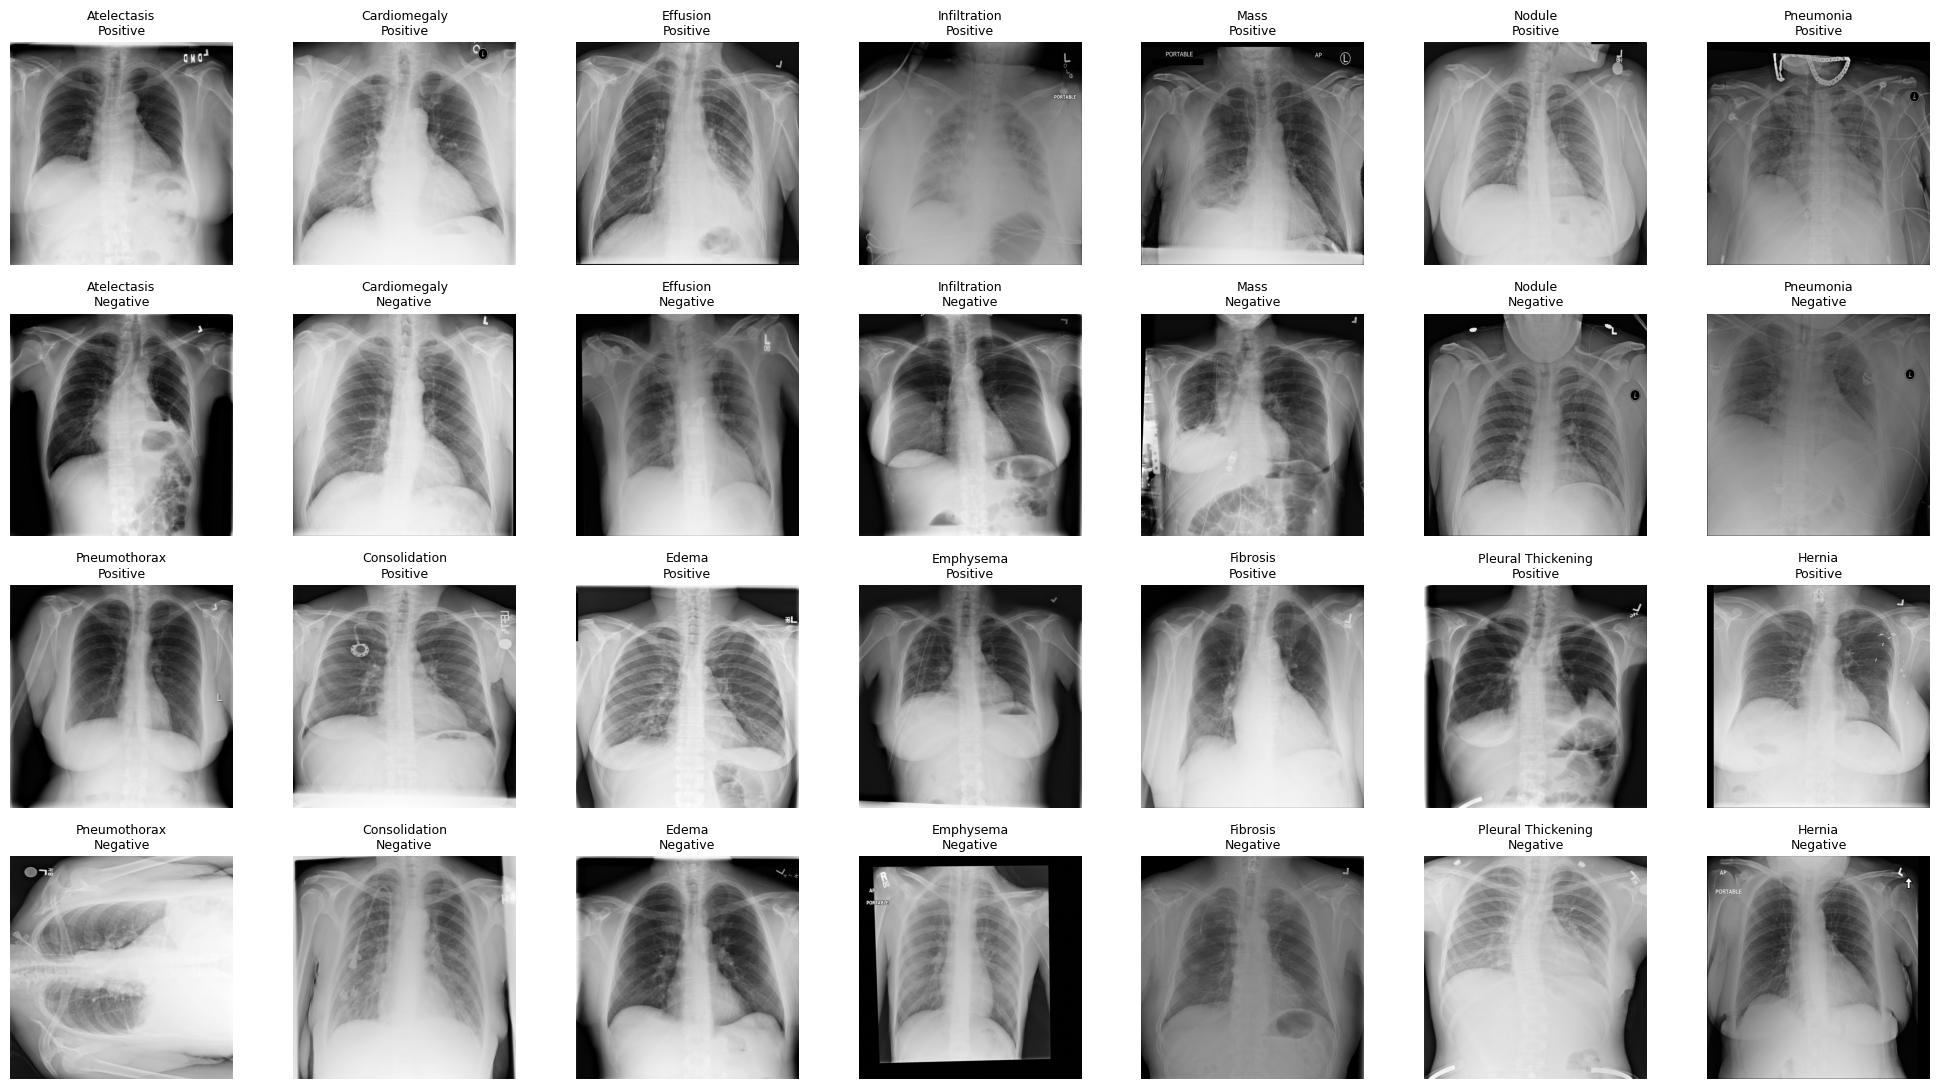

In [22]:
# Show positive and negative training samples for every finding
fig, axes = plt.subplots(4, 7, figsize=(20, 11))
for index, label in enumerate(LABELS):
    for offset, target in enumerate([1, 0]):
        ax = axes[(index // 7) * 2 + offset, index % 7]
        sample = frames['train'].loc[frames['train'][label].eq(target)].sample(1, random_state=0).iloc[0]
        with Image.open(sample.image_path) as image:
            ax.imshow(image.convert('L'), cmap='gray')
        ax.set_title(label.replace('_', ' ') + '\n' + ('Positive' if target else 'Negative'), fontsize=9)
        ax.axis('off')
fig.tight_layout()
fig.savefig(RESULTS / 'sample_images.png', dpi=160)
plt.show()
plt.close(fig)


In [23]:
# Find or download the verified pretrained weights
if PRETRAINED_WEIGHTS:
    checkpoint = Path(PRETRAINED_WEIGHTS)
else:
    attached = []
    for folder, directories, files in os.walk(INPUT):
        directories[:] = [d for d in directories if not d.startswith('images')]
        if 'chexworld_pretrained.tar' in files:
            attached.append(Path(folder) / 'chexworld_pretrained.tar')
    if len(attached) > 1:
        raise ValueError('Select one checkpoint with PRETRAINED_WEIGHTS.')
    checkpoint = attached[0] if attached else cw.download_weights(WORK / 'chexworld_pretrained.tar', CHECKPOINT_SHA256)
if cw.sha256(checkpoint) != CHECKPOINT_SHA256:
    raise ValueError('The checkpoint differs from the verified official release.')
print('Verified pretrained checkpoint:', checkpoint)


Verified pretrained checkpoint: /kaggle/working/chexworld_pretrained.tar


In [24]:
# Check the full encoder load and 14-output classifier
model = cw.make_model(checkpoint, DROP_PATH).eval()
sample, _, _ = cw.NIHImages(frames['train'])[0]
with torch.inference_mode():
    output = model(sample.unsqueeze(0))
if output.shape != (1, len(LABELS)) or not torch.isfinite(output).all():
    raise RuntimeError('Expected 14 finite classification logits.')
if not all(p.requires_grad for name, p in model.feature_model.named_parameters() if name != 'pos_embed'):
    raise RuntimeError('The encoder must be trainable apart from its fixed positional embedding.')
print(f'Strict encoder load passed | trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}')
del model, sample, output


/usr/lib/python3.13/contextlib.py:109: FutureWarning: `torch.backends.cuda.sdp_kernel()` is deprecated. In the future, this context manager will be removed. Please see `torch.nn.attention.sdpa_kernel()` for the new context manager, with updated signature.
  self.gen = func(*args, **kwds)


Strict encoder load passed | trainable parameters: 85,657,358


In [25]:
# Save the training configuration and environment details
cfg = dict(
    results=str(RESULTS), checkpoint=str(checkpoint), seeds=SEEDS, labels=LABELS,
    epochs=EPOCHS, warmup_epochs=WARMUP_EPOCHS, learning_rate=LEARNING_RATE,
    min_lr=MIN_LR, weight_decay=WEIGHT_DECAY, layer_decay=LAYER_DECAY,
    drop_path=DROP_PATH, micro_batch=MICRO_BATCH, accumulation=ACCUMULATION,
    effective_batch=MICRO_BATCH * GPU_COUNT * ACCUMULATION, eval_batch=EVAL_BATCH,
    workers=NUM_WORKERS, clip_grad=CLIP_GRAD, patience=PATIENCE, log_every=50,
    dataset='NIH ChestX-ray14', input_preparation='original PNG, official 224 classification transforms',
    input_size=224, resize_size=256, normalization='ImageNet default',
    optimizer='AdamW', betas=[0.9, 0.999], loss='unweighted BCEWithLogitsLoss', amp='FP16',
    repo_commit=REPO_COMMIT, checkpoint_sha256=CHECKPOINT_SHA256,
    source_hashes=SOURCE_HASHES, runtime_sha256=cw.sha256(RUNTIME),
    split_hashes=SPLIT_HASHES, manifest_hashes=manifest_hashes,
    **{split + '_manifest': str(RESULTS / f'{split}_manifest.csv') for split in frames}
)
config_path = RESULTS / 'config.json'
if config_path.exists():
    previous = json.loads(config_path.read_text())
    if cw.training_signature(previous) != cw.training_signature(cfg):
        raise ValueError('Training settings changed; choose a new RUN_NAME.')
config_path.write_text(json.dumps(cfg, indent=2))
(RESULTS / 'environment.txt').write_text(subprocess.check_output([sys.executable, '-m', 'pip', 'freeze'], text=True))
(RESULTS / 'hardware.json').write_text(json.dumps(dict(torch=torch.__version__, cuda=torch.version.cuda,
    gpus=[torch.cuda.get_device_name(i) for i in range(GPU_COUNT)]), indent=2))
setup_path = RESULTS / 'setup_times.json'
setup_times = json.loads(setup_path.read_text()) if setup_path.exists() else []
setup_times.append({'seconds': time.perf_counter() - SETUP_START})
setup_path.write_text(json.dumps(setup_times, indent=2))
print('Training configuration and environment details saved.')


Training configuration and environment details saved.


In [26]:
# Fine-tune and evaluate with both GPUs while saving the log
with socket.socket() as connection:
    connection.bind(('127.0.0.1', 0))
    port = connection.getsockname()[1]
command = [sys.executable, '-u', '-m', 'torch.distributed.run', '--nnodes=1',
    '--nproc_per_node=2', '--master_addr=127.0.0.1', f'--master_port={port}',
    str(RUNTIME), str(config_path)]
environment = os.environ.copy()
environment['OMP_NUM_THREADS'] = '2'
environment['PYTHONUNBUFFERED'] = '1'
environment['PYTHONPATH'] = str(WORK) + os.pathsep + environment.get('PYTHONPATH', '')
with (RESULTS / 'training.log').open('a') as log:
    process = subprocess.Popen(command, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
        text=True, bufsize=1, cwd=WORK, env=environment)
    for line in process.stdout:
        print(line, end='')
        log.write(line)
        log.flush()
    returncode = process.wait()
if returncode:
    raise RuntimeError(f'Training failed with exit code {returncode}; inspect training.log.')


Seed 0 | full encoder fine-tuning | 75,312 training images
/usr/lib/python3.13/contextlib.py:109: FutureWarning: `torch.backends.cuda.sdp_kernel()` is deprecated. In the future, this context manager will be removed. Please see `torch.nn.attention.sdpa_kernel()` for the new context manager, with updated signature.
  self.gen = func(*args, **kwds)
/usr/lib/python3.13/contextlib.py:109: FutureWarning: `torch.backends.cuda.sdp_kernel()` is deprecated. In the future, this context manager will be removed. Please see `torch.nn.attention.sdpa_kernel()` for the new context manager, with updated signature.
  self.gen = func(*args, **kwds)
Epoch 01/15 | update 1/294 | loss 0.7239 | LR 0.000000
Epoch 01/15 | update 50/294 | loss 0.4855 | LR 0.000017
Epoch 01/15 | update 100/294 | loss 0.1885 | LR 0.000034
Epoch 01/15 | update 150/294 | loss 0.1674 | LR 0.000051
Epoch 01/15 | update 200/294 | loss 0.1836 | LR 0.000068
Epoch 01/15 | update 250/294 | loss 0.1904 | LR 0.000085
Seed 0 | epoch 1 trainin

In [27]:
# Summarize the completed runs and per-class metrics
summaries, tables = [], []
for seed in SEEDS:
    directory = RESULTS / f'seed{seed}'
    if not (directory / 'summary.json').exists():
        continue
    summaries.append(json.loads((directory / 'summary.json').read_text()))
    table = pd.read_csv(directory / 'metrics.csv')
    table['seed'] = seed
    tables.append(table)
if not summaries:
    raise RuntimeError('No seed completed; inspect training.log.')
summary = pd.DataFrame(summaries)
summary.to_csv(RESULTS / 'run_summary.csv', index=False)
all_metrics = pd.concat(tables, ignore_index=True)
combined = all_metrics.groupby('label', sort=False).agg({column: ['mean', 'std'] for column in
    ['AUROC', 'AUPRC', 'accuracy', 'precision', 'recall', 'F1']})
combined.to_csv(RESULTS / 'metrics_across_seeds.csv')
display(combined.round(4))
print(f'Completed {len(summary)}/{len(SEEDS)} seeds | macro AUROC {summary.macro_auroc.mean():.4f}' +
    (f' ± {summary.macro_auroc.std(ddof=1):.4f}' if len(summary) > 1 else ' (single run)'))
print(f'Total full fine-tuning time: {summary.training_seconds.sum() / 3600:.2f} hours')
FIGURE_SEED = int(summary.seed.iloc[0])
figure_dir = RESULTS / f'seed{FIGURE_SEED}'


AUROC       AUPRC     accuracy     precision      recall  \
                      mean std    mean std     mean std      mean std    mean   
label                                                                           
Atelectasis         0.7920 NaN  0.3747 NaN   0.8300 NaN    0.3719 NaN  0.4748   
Cardiomegaly        0.9015 NaN  0.3662 NaN   0.9544 NaN    0.4482 NaN  0.3929   
Effusion            0.8426 NaN  0.5444 NaN   0.8127 NaN    0.4887 NaN  0.6372   
Infiltration        0.7130 NaN  0.4057 NaN   0.6213 NaN    0.3588 NaN  0.7444   
Mass                0.8408 NaN  0.3388 NaN   0.9191 NaN    0.4017 NaN  0.3764   
Nodule              0.7673 NaN  0.2079 NaN   0.8903 NaN    0.2424 NaN  0.3432   
Pneumonia           0.7263 NaN  0.0535 NaN   0.8497 NaN    0.0563 NaN  0.3766   
Pneumothorax        0.8812 NaN  0.4463 NaN   0.8838 NaN    0.4544 NaN  0.5764   
Consolidation       0.7639 NaN  0.1780 NaN   0.7814 NaN    0.1738 NaN  0.5548   
Edema               0.8640 NaN  0.2133 NaN   0.9541 NaN    0.2939 NaN  0.1935   
Emphysema           0.9273 NaN  0.4417 NaN   0.9469 NaN    0.4191 NaN  0.6276   
Fibrosis            0.8372 NaN  0.1054 NaN   0.9647 NaN    0.1599 NaN  0.2529   
Pleural_Thickening  0.8039 NaN  0.1656 NaN   0.9073 NaN    0.1959 NaN  0.3465   
Hernia              0.8488 NaN  0.1631 NaN   0.9966 NaN    0.0000 NaN  0.0000   

                            F1      
                   std    mean std  
label                               
Atelectasis        NaN  0.4171 NaN  
Cardiomegaly       NaN  0.4187 NaN  
Effusion           NaN  0.5532 NaN  
Infiltration       NaN  0.4842 NaN  
Mass               NaN  0.3887 NaN  
Nodule             NaN  0.2841 NaN  
Pneumonia          NaN  0.0980 NaN  
Pneumothorax       NaN  0.5082 NaN  
Consolidation      NaN  0.2647 NaN  
Edema              NaN  0.2334 NaN  
Emphysema          NaN  0.5026 NaN  
Fibrosis           NaN  0.1959 NaN  
Pleural_Thickening NaN  0.2503 NaN  
Hernia             NaN  0.0000 NaN

Completed 1/1 seeds | macro AUROC 0.8221 (single run)
Total full fine-tuning time: 4.32 hours


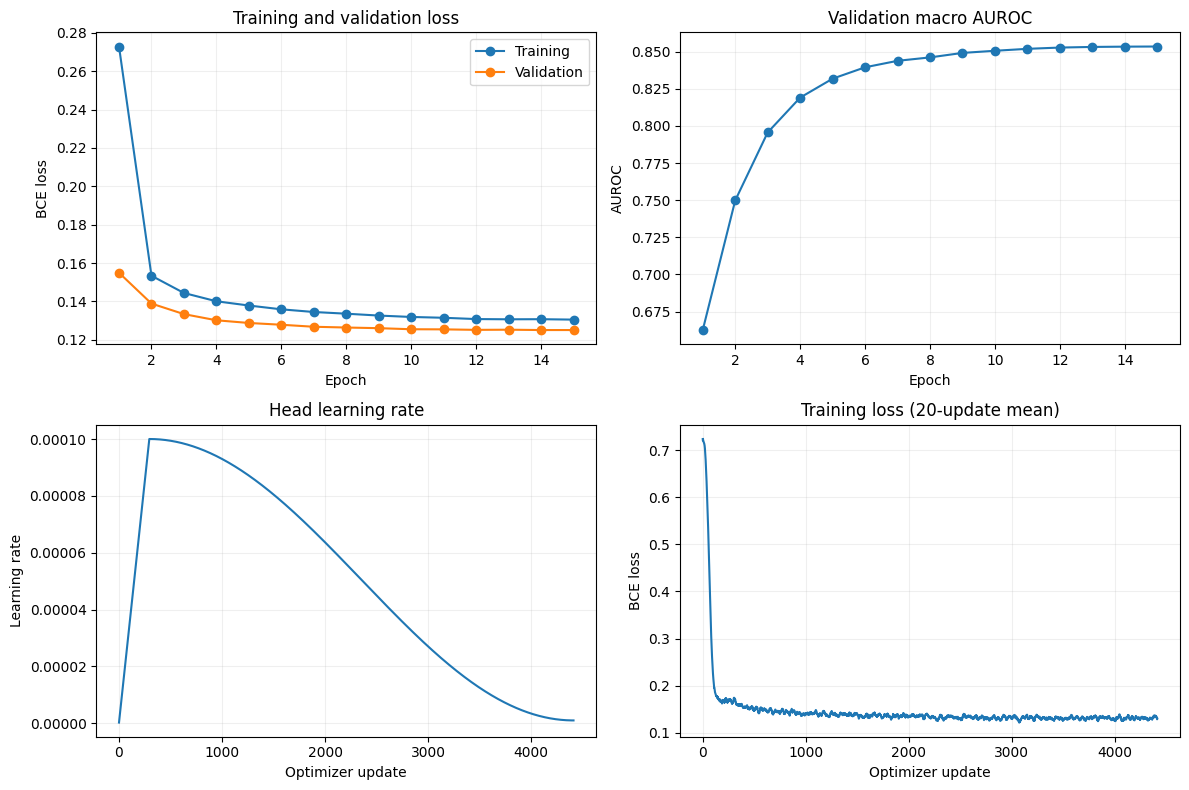

In [28]:
# Plot training loss, validation performance, and learning rate
history = pd.read_csv(figure_dir / 'history.csv')
steps = pd.read_csv(figure_dir / 'steps.csv')
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes[0, 0].plot(history.epoch, history.train_loss, 'o-', label='Training')
axes[0, 0].plot(history.epoch, history.val_loss, 'o-', label='Validation')
axes[0, 0].set(title='Training and validation loss', xlabel='Epoch', ylabel='BCE loss')
axes[0, 0].legend()
axes[0, 1].plot(history.epoch, history.val_auroc, 'o-')
axes[0, 1].set(title='Validation macro AUROC', xlabel='Epoch', ylabel='AUROC')
axes[1, 0].plot(np.arange(1, len(steps) + 1), steps.lr)
axes[1, 0].set(title='Head learning rate', xlabel='Optimizer update', ylabel='Learning rate')
axes[1, 1].plot(np.arange(1, len(steps) + 1), steps.loss.rolling(20, min_periods=1).mean())
axes[1, 1].set(title='Training loss (20-update mean)', xlabel='Optimizer update', ylabel='BCE loss')
for ax in axes.flat:
    ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(figure_dir / 'learning_curves.png', dpi=180)
plt.show()
plt.close(fig)


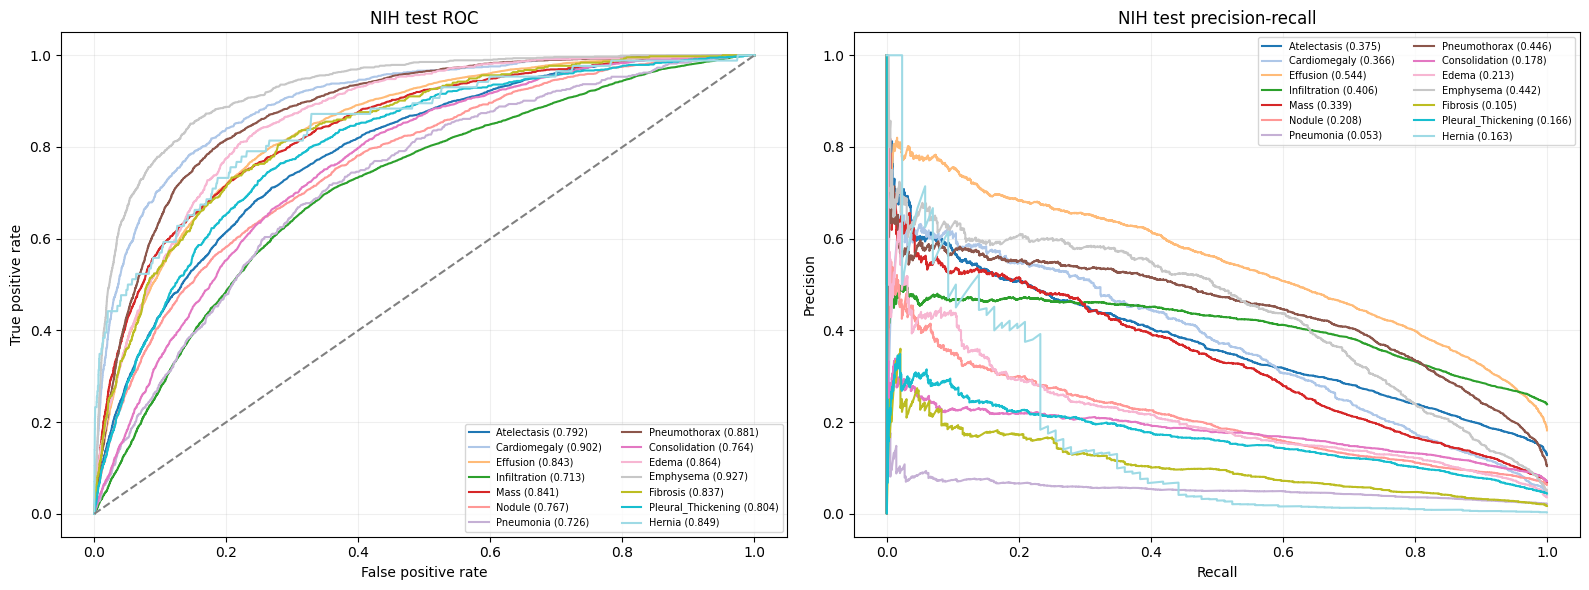

In [29]:
# Plot the held-out test ROC and precision-recall curves
predictions = pd.read_csv(figure_dir / 'test_predictions.csv')
metrics = pd.read_csv(figure_dir / 'metrics.csv').set_index('label')
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
colors = plt.cm.tab20(np.linspace(0, 1, len(LABELS)))
for label, color in zip(LABELS, colors):
    truth, probability = predictions[label], predictions[label + '_probability']
    fpr, tpr, _ = roc_curve(truth, probability)
    precision, recall, _ = precision_recall_curve(truth, probability)
    axes[0].plot(fpr, tpr, color=color, label=f'{label} ({metrics.loc[label, "AUROC"]:.3f})')
    axes[1].plot(recall, precision, color=color, label=f'{label} ({metrics.loc[label, "AUPRC"]:.3f})')
axes[0].plot([0, 1], [0, 1], '--', color='gray')
axes[0].set(title='NIH test ROC', xlabel='False positive rate', ylabel='True positive rate')
axes[1].set(title='NIH test precision-recall', xlabel='Recall', ylabel='Precision')
for ax in axes:
    ax.legend(fontsize=7, ncol=2)
    ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(figure_dir / 'roc_pr_curves.png', dpi=180)
plt.show()
plt.close(fig)


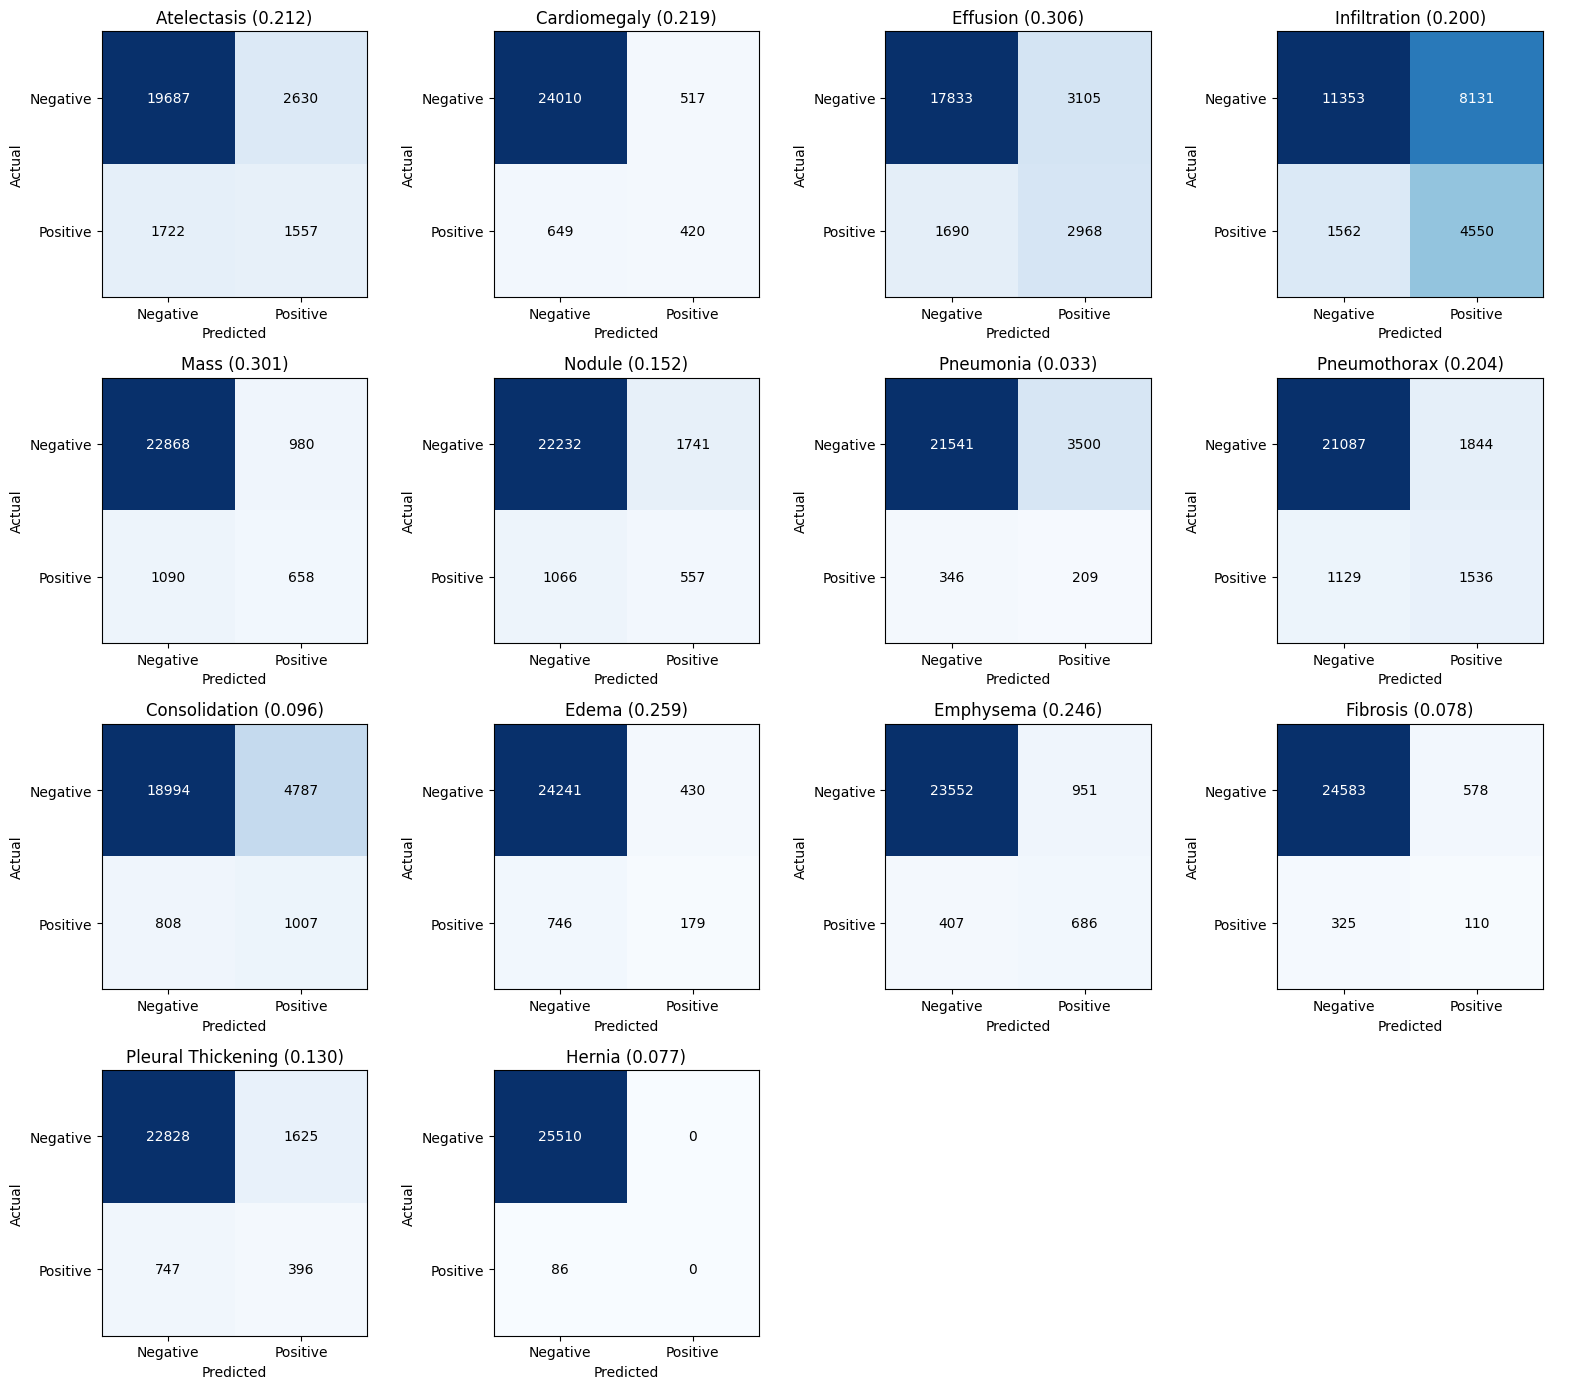

In [30]:
# Plot confusion matrices at validation-selected thresholds
fig, axes = plt.subplots(4, 4, figsize=(16, 14))
for index, label in enumerate(LABELS):
    ax = axes.flat[index]
    threshold = metrics.loc[label, 'threshold']
    matrix = confusion_matrix(predictions[label], predictions[label + '_probability'] >= threshold, labels=[0, 1])
    ax.imshow(matrix, cmap='Blues', vmin=0, vmax=max(1, matrix.max()))
    for row in range(2):
        for column in range(2):
            ax.text(column, row, str(matrix[row, column]), ha='center', va='center',
                color='white' if matrix[row, column] > matrix.max() / 2 else 'black')
    ax.set(title=f'{label.replace("_", " ")} ({threshold:.3f})', xlabel='Predicted', ylabel='Actual',
        xticks=[0, 1], yticks=[0, 1], xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
for ax in list(axes.flat)[len(LABELS):]:
    ax.axis('off')
fig.tight_layout()
fig.savefig(figure_dir / 'confusion_matrices.png', dpi=180)
plt.show()
plt.close(fig)


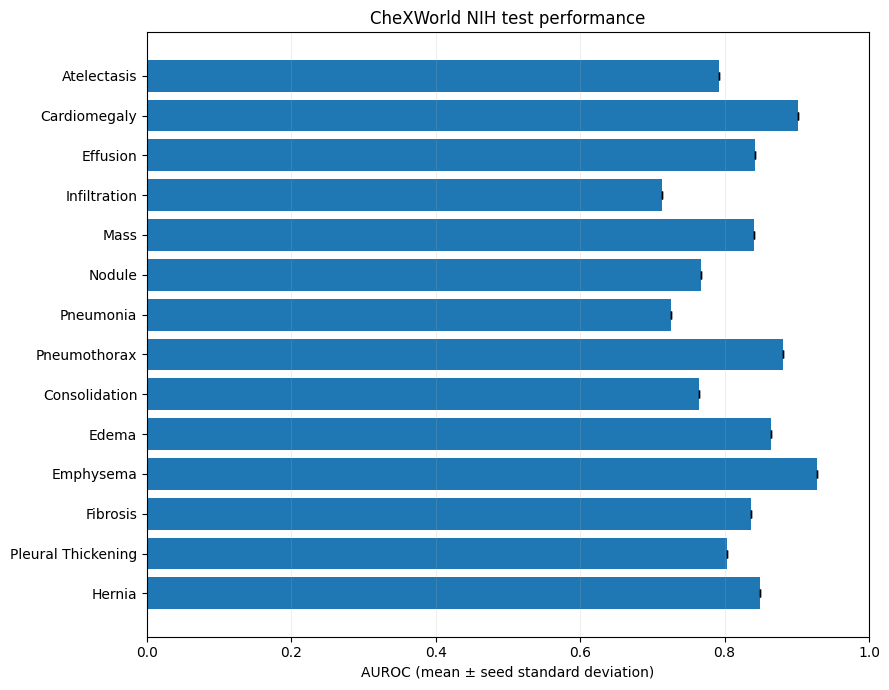

In [31]:
# Plot class-wise AUROC across the completed runs
mean_auc = combined[('AUROC', 'mean')].reindex(LABELS)
std_auc = combined[('AUROC', 'std')].reindex(LABELS).fillna(0)
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(np.arange(len(LABELS)), mean_auc, xerr=std_auc, capsize=3)
ax.set(yticks=np.arange(len(LABELS)), yticklabels=[label.replace('_', ' ') for label in LABELS],
       xlim=(0, 1), xlabel='AUROC (mean ± seed standard deviation)', title='CheXWorld NIH test performance')
ax.invert_yaxis()
ax.grid(axis='x', alpha=0.2)
fig.tight_layout()
fig.savefig(RESULTS / 'class_auroc.png', dpi=180)
plt.show()
plt.close(fig)


In [32]:
# Display the saved run timing and output location
display(summary[['seed', 'epochs_completed', 'best_epoch', 'macro_auroc', 'training_seconds',
                 'validation_seconds', 'test_seconds', 'total_seconds', 'peak_gpu_memory_mb']].round(3))
print('Results:', RESULTS)
print('Saved: checkpoints, settings, split manifests, predictions, metrics, figures, logs, and timing.')


,seed,epochs_completed,best_epoch,macro_auroc,training_seconds,validation_seconds,test_seconds,total_seconds,peak_gpu_memory_mb
0,0,15,15,0.822,15569.228,2190.071,337.107,18137.756,3930.185


Results: /kaggle/working/chexworld_nih
Saved: checkpoints, settings, split manifests, predictions, metrics, figures, logs, and timing.
